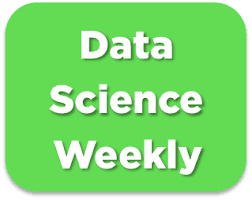

# Import libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import r2_score
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from sklearn.model_selection import cross_val_score

import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings(
    "ignore", category=DeprecationWarning
)  # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

from IPython.display import display

# Read file with labels

In [2]:
df = pd.read_csv("walmart_sales.csv")

# Preprocessing

## preprocessing pandas

In [3]:
df.columns = df.columns.str.lower()
print(df.columns)

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment'],
      dtype='str')


### Missing values

In [4]:
print('Missing values treatment...')
# before = df.nunique()
cols = ['weekly_sales', 'date']
df = df.dropna(subset=cols) # drop lines where target values is missing. 

Missing values treatment...


### Convert data

In [5]:
categories = ['store', 'holiday_flag']

df[categories] = df[categories].astype('Int64') # convert categories in integers, avoid error "Cannot convert non-finite values".

In [6]:
# Conversion des dates au format date time
type('date')
df['date'] = pd.to_datetime(df['date'], format = "%d-%m-%Y")
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['weekday'] = df['date'].dt.dayofweek
print(df['weekday'].value_counts(dropna=False))

weekday
4    118
Name: count, dtype: int64


In [7]:
numerical_cols = ['fuel_price', 'cpi', 'unemployment']
df[numerical_cols] = df[numerical_cols].round(2)
print(df[categories + ['date']].dtypes)

store                    Int64
holiday_flag             Int64
date            datetime64[us]
dtype: object


In [8]:
df=df.drop('date', axis=1)

In [9]:
df.head(1)

,store,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,year,month,day,weekday
0,6,1572117.54,<NA>,59.61,3.04,214.78,6.86,2011,2,18,4


### mask outlyers

In [10]:
mean = df['unemployment'].mean()
sigma = df['unemployment'].std()

mask = df['unemployment'].between(mean - 3 * sigma, mean + 3 * sigma)
df = df[mask]
print(df.shape)

(102, 11)


In [11]:
### drop store 11
count = df['store'].value_counts()
count[count < 2]
df = df.drop(df[df['store'] < 2].index)
df['store'].value_counts()
mask = df['store'].isin(count[count < 2].index)
df = df.drop(df[mask].index)
print(df[df['store'] < 2]) 
df.head(1)

Empty DataFrame
Columns: [store, weekly_sales, holiday_flag, temperature, fuel_price, cpi, unemployment, year, month, day, weekday]
Index: []


,store,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,year,month,day,weekday
0,6,1572117.54,<NA>,59.61,3.04,214.78,6.86,2011,2,18,4


# Baseline model

## preprocessing en sklearn

### Multivariate linear regression

#### Separate target variable Y from features X

In [12]:
# Separate target variable Y from features X

print("Separating labels from features...")
target = 'weekly_sales'

y = df.loc[:, target]# or df.iloc[:, -1] # or  df.loc[:, df.columns == target]
X = df.drop(target, axis=1) # or df.iloc[:, 0:-1]  # All columns are kept, except the target
# or df.loc[:, df.columns != target]
print("...Done.")

print("y : ")
print(y.head())
print()
print("X : ")
print(X.head())

Separating labels from features...
...Done.
y : 
0    1572117.54
1    1807545.43
4    1644470.66
5    1857533.70
6     695396.19
Name: weekly_sales, dtype: float64

X : 
   store  holiday_flag  temperature  fuel_price     cpi  unemployment  year  \
0      6          <NA>        59.61        3.04  214.78          6.86  2011   
1     13             0        42.38        3.44  128.62          7.47  2011   
4      6             0        78.89        2.76  212.41          7.09  2010   
5      4             0          NaN        2.76  126.16          7.90  2010   
6     15             0        69.80        4.07  134.86          7.66  2011   

   month  day  weekday  
0      2   18        4  
1      3   25        4  
4      5   28        4  
5      5   28        4  
6      6    3        4  


In [13]:
'''# Automatically detect names of numeric/categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Found numeric features ", numeric_features)
print("Found categorical features ", categorical_features)'''

'# Automatically detect names of numeric/categorical columns\nnumeric_features = X.select_dtypes(include="number").columns.tolist()\ncategorical_features = X.select_dtypes(exclude="number").columns.tolist()\n\nprint("Found numeric features ", numeric_features)\nprint("Found categorical features ", categorical_features)'

In [14]:
numeric_features = ['temperature', 'fuel_price', 'cpi', 'unemployment', 'year', 'month', 'day', 'weekday']
categorical_features = ['store', 'holiday_flag']

Remember to treat year, 'month', 'day', 'weekday' as numeric features (cf instructions)

#### Divide dataset train set & test set 

We apply different transformations to the features, depending on their types. Numeric columns will be standardized whereas categorical columns will be one-hot-encoded. As regards missing values imputation, it can apply to every column, but different rules may be used. 

In [15]:
# Divide dataset Train set & Test set
print("Dividing into train and test sets...")
# WARNING : don't forget stratify=Y for classification problems
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['store']
)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



We'll use simple imputer because we don't have any missing values. num_imputer = SimpleImputer(strategy="median")

We normalize numeric colomns to scale them down.

#### pipelines

In [16]:
print("Preprocessing X_train...")
print(X_train.head())
print()

# categoric

cat_transformer = Pipeline(steps=[
    ('cat_imputer', SimpleImputer(strategy="most_frequent")),
    ('catEncoder', OneHotEncoder(drop='first'))
])
# numerical

num_transformer = Pipeline(steps=[
    ('num_imputer', SimpleImputer(strategy="median")),
    ('scaler', StandardScaler())
])

Preprocessing X_train...
     store  holiday_flag  temperature  fuel_price     cpi  unemployment  year  \
46       5             0        82.46        2.64  211.93          6.50  2010   
141      5             0        62.37         NaN  212.56          6.77  2010   
45       2             0        54.63        3.56  220.28          7.06  2012   
36       3             0        80.19        3.47  219.74          7.57  2011   
18       2             0        50.13         NaN     NaN          7.44  2011   

     month  day  weekday  
46       7   30        4  
141     11   12        4  
45       2   24        4  
36       9   23        4  
18      12   16        4  



In [17]:
#### pipeline global
print("Encoding categorical features and standardizing numerical features...")

preprocessor = ColumnTransformer(transformers=[
    ('cat_transformer', cat_transformer, categorical_features),
    ('num_transformer', num_transformer, numeric_features)
])

# Preprocessings on train set
print("Preprocessing sur le train set...")
X_train = preprocessor.fit_transform(X_train)
print('...Terminé.')
X_train[0:5] # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore
print()


Encoding categorical features and standardizing numerical features...
Preprocessing sur le train set...
...Terminé.



Nous n'utilisons pas labelEncoder sur y_test car les labels sont déjà convertis sur converted

#### Test pipeline

In [18]:
# Preprocessings sur le test set
print("Preprocessing on test set...")
X_test = preprocessor.transform(X_test) # Don't fit again !! The test set is used for validating decisions
# we made based on the training set, therefore we can only apply transformations that were parametered using the training set.
# Otherwise this creates what is called a leak from the test set which will introduce a bias in all your results.
print('...Done.')
X_test[:5, :] # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore

Preprocessing on test set...
...Done.


array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  1.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00, -6.56605373e-01,
         2.85975194e-01,  9.58130187e-01, -1.05097993e+00,
        -1.10660574e+00, -1.13169683e+00, -5.97450129e-01,
         0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  1.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  1.57109854e+00,
         7.15797630e-01, -1.30641083e+00, -1.99944432e-01,
         1.33443634e+00,  2.26339365e-01, -1.33809078e+00,
         0.00000000e+00],
    

#### Train model

In [19]:

from sklearn.linear_model import LinearRegression

print("Train model...")
baseline = LinearRegression() # 
baseline.fit(X_train, y_train)
print("...Done.")

Train model...
...Done.


#### Performance evaluation

## Cross validation

In [20]:
# Perform 10-fold cross-validation
print("5-fold cross-validation...")
scores = cross_val_score(baseline, X_train, y_train, cv=(10))
print('The cross-validated accuracy is : ', scores.mean())
print('The standard deviation is : ', scores.std())

5-fold cross-validation...
The cross-validated accuracy is :  0.9092875241763547
The standard deviation is :  0.07482464180642971


#### Predictions

In [21]:
# Predictions on training set
print("Predictions on training set...")
y_train_pred = baseline.predict(X_train)
print("...Done.")
print(y_train_pred)
print()

Predictions on training set...
...Done.
[ 261264.55322448  380471.76381271 1901626.2303992   312899.71363017
 2052941.39909079  625725.33110113 2045833.68900889  976071.21685326
  588551.14132387  992154.40580058 1931378.05742246 1946149.39638688
  870580.75963275  371667.86616921  143129.99201646  572109.15691163
  204839.02252081 1350459.10061     451774.66973768  535528.88008762
  554278.84110122 2108598.70415097 1605938.9381121   460481.38842552
 1937686.13248218 1998978.69025713 2082389.45034725 1381188.9280653
 2039155.11021779  491339.26096092 1449308.65139871 2309865.40463051
  552291.85335069  543899.86409799 2106084.39819924 2047568.13413339
 1381704.49509909  527486.89156885  462934.13991238  307011.89588459
  484983.65770836 2079188.82399676  916589.41447793 1469384.36073471
 2061608.79432727  414912.67809538 2068768.44432696  372817.82565741
 1906848.53258589  677456.27867613 1155517.86808848  397149.00711873
  452713.14934655 1181877.57719674 1932445.67016277  926371.2551

In [22]:
# Predictions on test set
print("Predictions on test set...")
y_test_pred = baseline.predict(X_test)
print("...Done.")
print(y_test_pred)
print()

Predictions on test set...
...Done.
[ 881645.74810078 2082518.28668822 2005515.1633995   619288.80614421
  470405.50955517 1974707.72794432  487498.52582094  381745.6961399
 1499459.50543909  470019.58779699  950557.67760609 1924249.32822027
 1413460.36240544 2117372.70968701 1540190.54587833 2118073.76786473
  888405.61193748 2058543.27963393  513989.86654239]



In [23]:
# Print R^2 scores
print("R2 score on training set : ", r2_score(y_train, y_train_pred))
print("R2 score on test set : ", r2_score(y_test, y_test_pred))

R2 score on training set :  0.9784097471667802
R2 score on test set :  0.950761477137217


The baseline model overfits.

Interpreting the models coefficients

In [24]:
baseline.coef_

array([-1619329.85226431,   286666.91394222, -1773284.38100965,
        -440264.75930663, -1281920.26197346, -1205298.11433769,
       -1635231.7032551 ,   351534.00037394,   148190.47361848,
         368221.28058089, -1020438.24025351, -1541045.23459138,
       -1119106.94736295,  -548099.4737749 ,  -257483.30890987,
          32106.52262501,  -131178.02784488,   -47111.88420101,
         -47564.85600935,   104076.25942203,  -111838.00778516,
          -4662.40352874,    58921.59540049,   -42750.46459087,
              0.        ])

In [25]:
column_names = []
for name, pipeline, features_list in preprocessor.transformers_: # loop over pipelines
    if name == 'num_transformer': # if pipeline is for numeric variables
        features = features_list # just get the names of columns to which it has been applied
    else: # if pipeline is for categorical variables
        features = pipeline.named_steps['catEncoder'].get_feature_names_out() # get output columns names from OneHotEncoder
    column_names.extend(features) # concatenate features names

print("Names of columns corresponding to each coefficient: ", column_names)

Names of columns corresponding to each coefficient:  ['x0_3.0', 'x0_4.0', 'x0_5.0', 'x0_6.0', 'x0_7.0', 'x0_8.0', 'x0_9.0', 'x0_10.0', 'x0_13.0', 'x0_14.0', 'x0_15.0', 'x0_16.0', 'x0_17.0', 'x0_18.0', 'x0_19.0', 'x0_20.0', 'x1_1.0', 'temperature', 'fuel_price', 'cpi', 'unemployment', 'year', 'month', 'day', 'weekday']


In [26]:
# Create a pandas DataFrame
coefs = pd.DataFrame(index = column_names, data = baseline.coef_.transpose(), columns=["coefficients"])
coefs

,coefficients
x0_3.0,-1.619330e+06
x0_4.0,2.866669e+05
x0_5.0,-1.773284e+06
x0_6.0,-4.402648e+05
x0_7.0,-1.281920e+06
x0_8.0,-1.205298e+06
x0_9.0,-1.635232e+06
x0_10.0,3.515340e+05
x0_13.0,1.481905e+05
x0_14.0,3.682213e+05


In [27]:
# Compute abs() and sort values
feature_importance = abs(coefs).sort_values(by = 'coefficients')
feature_importance

,coefficients
weekday,0.000000e+00
year,4.662404e+03
x0_20.0,3.210652e+04
day,4.275046e+04
temperature,4.711188e+04
fuel_price,4.756486e+04
month,5.892160e+04
cpi,1.040763e+05
unemployment,1.118380e+05
x1_1.0,1.311780e+05


In [28]:
# Plot coefficients
fig = px.bar(feature_importance, orientation = 'h')
fig.update_layout(showlegend = False,
                  margin = {'l': 120} # to avoid cropping of column names
                 )
fig.show()

In [29]:
'''import matplotlib.pyplot as plt

plt.scatter(y_test, y_test_pred)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()'''

'import matplotlib.pyplot as plt\n\nplt.scatter(y_test, y_test_pred)\nplt.xlabel("Valeurs réelles")\nplt.ylabel("Valeurs prédites")\nplt.show()'

In [30]:
'''plt.scatter(y_test, y_test_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()'''

'plt.scatter(y_test, y_test_pred)\nplt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")\nplt.xlabel("Valeurs réelles")\nplt.ylabel("Valeurs prédites")\nplt.show()'

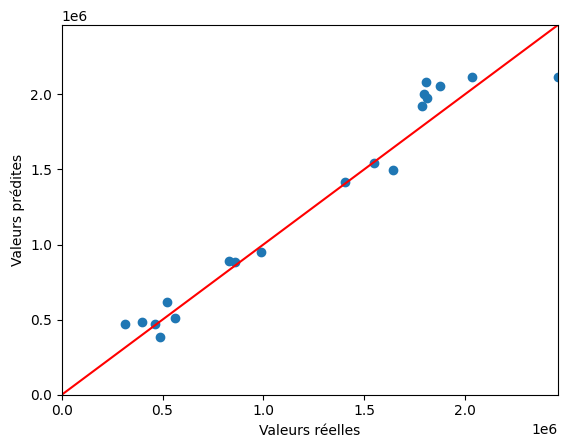

In [31]:
lim_max = max(y_test.max(), y_test_pred.max())

plt.scatter(y_test, y_test_pred)
plt.plot([0, lim_max], [0, lim_max], color="red")
plt.xlim(0, lim_max)
plt.ylim(0, lim_max)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()

In [32]:
'''plt.scatter(y_test, y_test_pred)
plt.xlim(0)
plt.ylim(0)
plt.show()'''

'plt.scatter(y_test, y_test_pred)\nplt.xlim(0)\nplt.ylim(0)\nplt.show()'